# Isolation Forest Demo

This notebook is a gentle introduction to **IsolationForest** for anomaly detection.

By the end, a new user should be able to:
- explain the basic idea behind isolation forests
- fit an IsolationForest model on a simple toy dataset
- interpret predictions and anomaly scores
- see how the `contamination` setting changes the final labels
- optionally explore a proximity-based view with `forestgap`


In [28]:
from pathlib import Path
import sys

def add_repo_root_to_path(marker: str = 'forestgap') -> Path:
    cwd = Path.cwd().resolve()
    for candidate in (cwd, *cwd.parents):
        if (candidate / marker).exists():
            path = str(candidate)
            if path not in sys.path:
                sys.path.insert(0, path)
            return candidate
    raise RuntimeError(f"Could not locate a repo root containing '{marker}'.")

REPO_ROOT = add_repo_root_to_path()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

from forestgap import with_sparse_proximity

plt.style.use('seaborn-v0_8-whitegrid')

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)


## 1. Intuition

Isolation forests work by repeatedly splitting the data with random trees.
Points that are easy to isolate tend to be unusual, so they receive more anomalous scores.

In practice, that means:
- points deep inside a dense cluster usually look normal
- points far from the main groups are often isolated quickly
- the model returns both a score and a final inlier or outlier label


In [29]:
N_SAMPLES = 320
TRUE_OUTLIER_FRACTION = 0.08
MODEL_CONTAMINATION = 0.08
N_ESTIMATORS = 300

print('Demo configuration')
print(f'  total samples:         {N_SAMPLES}')
print(f'  planted outlier share: {TRUE_OUTLIER_FRACTION:.0%}')
print(f'  model contamination:   {MODEL_CONTAMINATION:.0%}')
print(f'  number of trees:       {N_ESTIMATORS}')


Demo configuration
  total samples:         320
  planted outlier share: 8%
  model contamination:   8%
  number of trees:       300


## 2. Create a toy dataset

We will make three compact clusters and then inject a small number of obvious outliers.
For teaching purposes, we know which points are truly anomalous, so we can compare the model's predictions to ground truth.


In [30]:
n_inliers = int(N_SAMPLES * (1 - TRUE_OUTLIER_FRACTION))
n_outliers = N_SAMPLES - n_inliers

X_inliers, _ = make_blobs(
    n_samples=n_inliers,
    centers=[(-3.0, -2.0), (0.0, 2.5), (3.5, -0.5)],
    cluster_std=[0.75, 0.95, 0.70],
    random_state=RANDOM_STATE,
)

X_outliers = rng.uniform(
    low=np.array([-8.0, -7.0]),
    high=np.array([8.0, 7.0]),
    size=(n_outliers, 2),
)

X_raw = np.vstack([X_inliers, X_outliers])
y_true = np.hstack([
    np.zeros(n_inliers, dtype=int),
    np.ones(n_outliers, dtype=int),
])

permutation = rng.permutation(N_SAMPLES)
X_raw = X_raw[permutation]
y_true = y_true[permutation]

feature_names = ['feature_1', 'feature_2']
X_frame = pd.DataFrame(X_raw, columns=feature_names)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_frame)

print(f'Inliers:  {n_inliers}')
print(f'Outliers: {n_outliers}')
X_frame.head()


Inliers:  294
Outliers: 26


,feature_1,feature_2
0,0.519743,2.307917
1,-3.010123,-2.793283
2,-2.131053,-2.615512
3,-0.679539,3.145618
4,0.906302,3.118822


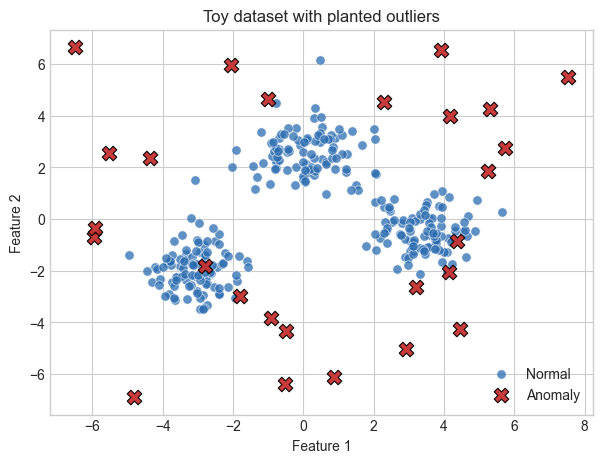

In [31]:
def scatter_anomalies(X, labels, ax, title):
    normal_mask = labels == 0
    anomaly_mask = labels == 1

    ax.scatter(
        X[normal_mask, 0],
        X[normal_mask, 1],
        s=45,
        alpha=0.75,
        c='#2b6cb0',
        edgecolors='white',
        linewidth=0.5,
        label='Normal',
    )
    ax.scatter(
        X[anomaly_mask, 0],
        X[anomaly_mask, 1],
        s=110,
        alpha=0.95,
        c='#c53030',
        marker='X',
        edgecolors='black',
        linewidth=0.8,
        label='Anomaly',
    )
    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend(loc='best')

fig, ax = plt.subplots(figsize=(7, 5))
scatter_anomalies(X_raw, y_true, ax, 'Toy dataset with planted outliers')
plt.show()


## 3. Fit a plain IsolationForest

We will start with the standard scikit-learn estimator.
The model is fit on the standardized features, but we will keep plotting the original coordinates because they are easier to interpret visually.


In [32]:
iso_forest = IsolationForest(
    n_estimators=N_ESTIMATORS,
    contamination=MODEL_CONTAMINATION,
    random_state=RANDOM_STATE,
)

iso_forest.fit(X_scaled)

predictions = iso_forest.predict(X_scaled)
predicted_anomaly = (predictions == -1).astype(int)

decision_function = iso_forest.decision_function(X_scaled)
outlier_score = -iso_forest.score_samples(X_scaled)

print(f'Flagged as anomalies: {predicted_anomaly.sum()}')
print(f'Flagged as normal:    {(predicted_anomaly == 0).sum()}')


Flagged as anomalies: 26
Flagged as normal:    294


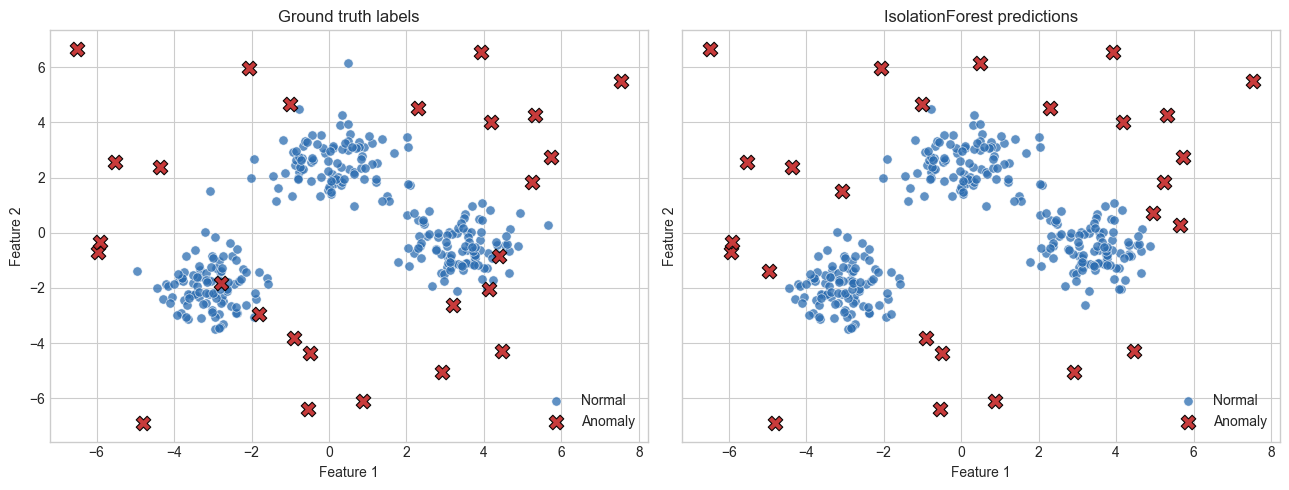

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
scatter_anomalies(X_raw, y_true, axes[0], 'Ground truth labels')
scatter_anomalies(X_raw, predicted_anomaly, axes[1], 'IsolationForest predictions')
plt.tight_layout()
plt.show()


## 4. Read the outputs

`predict` returns final labels.
`decision_function` is centered around the model's threshold, so negative values are labeled as outliers.
For easy ranking, we also create `outlier_score = -score_samples`, where **larger means more anomalous**.


In [34]:
tn, fp, fn, tp = confusion_matrix(y_true, predicted_anomaly).ravel()

print('Confusion matrix counts')
print(f'  true negatives:  {tn}')
print(f'  false positives: {fp}')
print(f'  false negatives: {fn}')
print(f'  true positives:  {tp}')
print()
print('Top 10 points by outlier score')

results = X_frame.copy()
results['true_anomaly'] = y_true
results['predicted_anomaly'] = predicted_anomaly
results['decision_function'] = decision_function
results['outlier_score'] = outlier_score

results.sort_values('outlier_score', ascending=False).head(10)


Confusion matrix counts
  true negatives:  289
  false positives: 5
  false negatives: 5
  true positives:  21

Top 10 points by outlier score


,feature_1,feature_2,true_anomaly,predicted_anomaly,decision_function,outlier_score
212,-6.493162,6.658713,1,1,-0.234335,0.760662
29,-4.801469,-6.896928,1,1,-0.215793,0.742119
98,7.531168,5.503696,1,1,-0.214608,0.740935
227,-0.532464,-6.386747,1,1,-0.161185,0.687511
135,0.873357,-6.106558,1,1,-0.159712,0.686039
132,3.916194,6.545136,1,1,-0.152069,0.678395
223,-2.067232,5.974710,1,1,-0.130623,0.656949
232,-5.531368,2.562685,1,1,-0.124609,0.650935
107,4.454136,-4.275058,1,1,-0.124269,0.650595
128,-5.921256,-0.340131,1,1,-0.115138,0.641465


## 5. Change one parameter: `contamination`

`contamination` does **not** teach the model what anomalies look like.
Instead, it sets the fraction of points that should end up on the anomaly side of the threshold.

Below we compare two ways to convert a fitted forest into anomaly labels:
- the native `IsolationForest.predict` threshold
- a proximity-based Breiman outlier score computed from **OOB proximities**, then thresholded at the same contamination rate
- a disagreement view that highlights points flagged by only one of the two methods

Using the same contamination rate for both makes it easier to see how the *scoring rule* changes the flagged points.


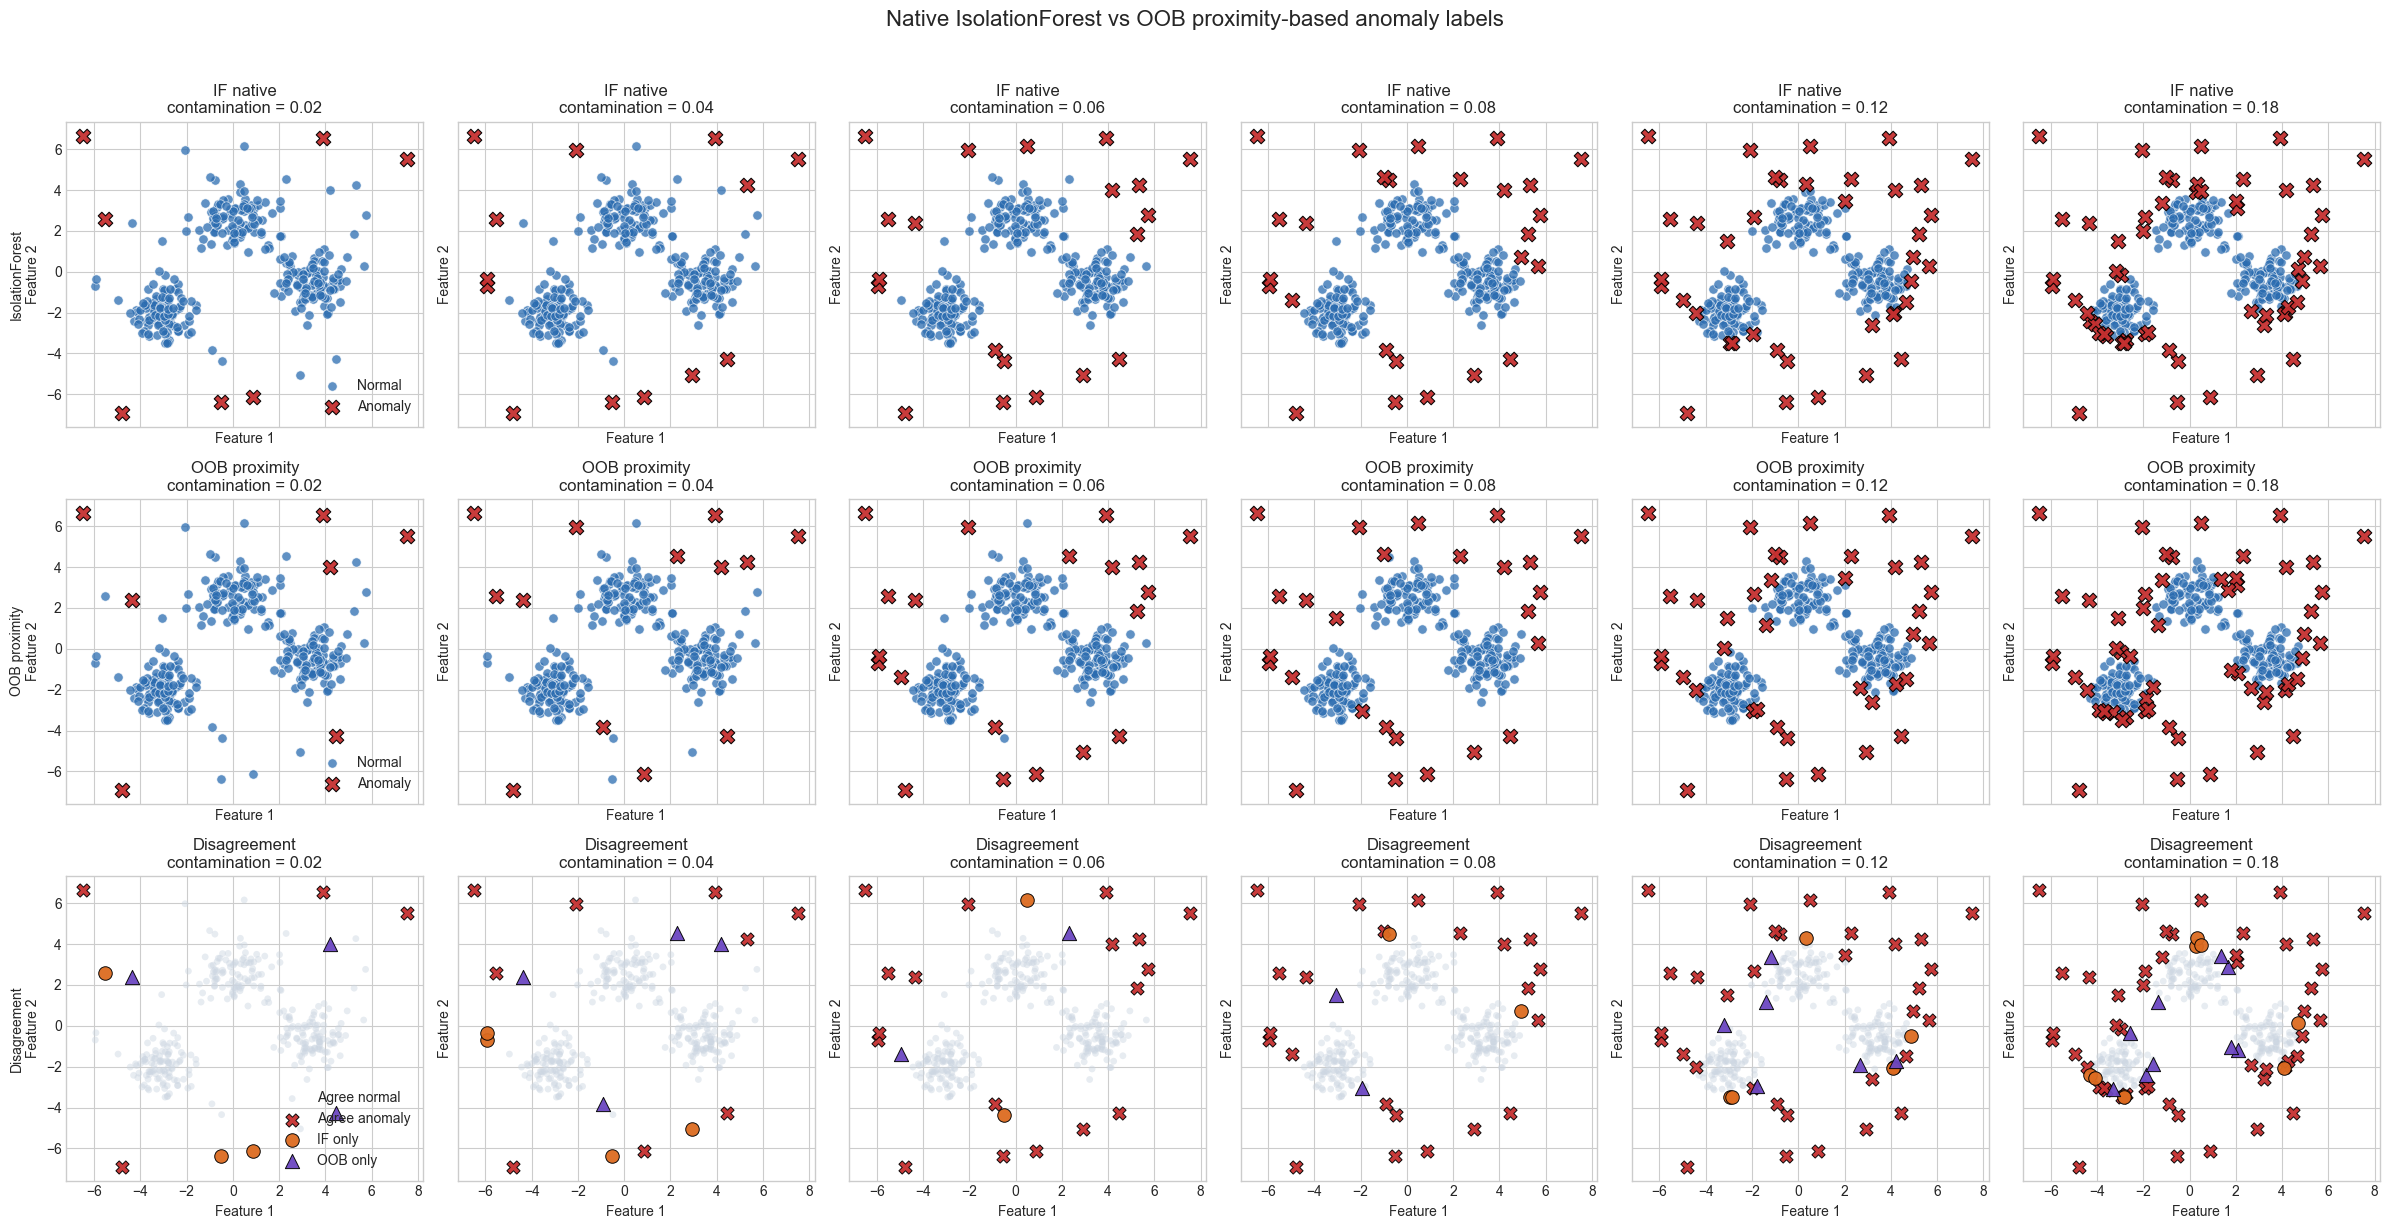

,method,contamination,flagged_as_anomaly,true_positives,false_positives,agree_with_other_method,if_only,oob_only,score_threshold
0,IsolationForest,0.02,7,7,0,4,3,3,
1,OOB proximity score,0.02,7,7,0,4,3,3,14.819853
2,IsolationForest,0.04,13,13,0,9,4,4,
3,OOB proximity score,0.04,13,13,0,9,4,4,12.455528
4,IsolationForest,0.06,20,19,1,18,2,2,
5,OOB proximity score,0.06,20,19,1,18,2,2,9.287609
6,IsolationForest,0.08,26,21,5,24,2,2,
7,OOB proximity score,0.08,26,21,5,24,2,2,6.70985
8,IsolationForest,0.12,39,23,16,33,6,6,
9,OOB proximity score,0.12,39,23,16,33,6,6,3.931042


In [35]:
ProxIsolationForest = with_sparse_proximity(IsolationForest)

def top_contamination_labels(scores, contamination):
    n_flagged = max(1, int(np.ceil(contamination * len(scores))))
    threshold = np.sort(scores)[::-1][n_flagged - 1]
    return (scores >= threshold).astype(int), threshold

def scatter_disagreement(X, iso_labels, prox_labels, ax, title):
    both_normal = (iso_labels == 0) & (prox_labels == 0)
    both_anomaly = (iso_labels == 1) & (prox_labels == 1)
    iso_only = (iso_labels == 1) & (prox_labels == 0)
    prox_only = (iso_labels == 0) & (prox_labels == 1)

    ax.scatter(
        X[both_normal, 0],
        X[both_normal, 1],
        s=24,
        alpha=0.45,
        c='#cbd5e1',
        edgecolors='none',
        label='Agree normal',
    )
    ax.scatter(
        X[both_anomaly, 0],
        X[both_anomaly, 1],
        s=90,
        alpha=0.95,
        c='#c53030',
        marker='X',
        edgecolors='black',
        linewidth=0.7,
        label='Agree anomaly',
    )
    ax.scatter(
        X[iso_only, 0],
        X[iso_only, 1],
        s=95,
        alpha=0.95,
        c='#dd6b20',
        marker='o',
        edgecolors='black',
        linewidth=0.7,
        label='IF only',
    )
    ax.scatter(
        X[prox_only, 0],
        X[prox_only, 1],
        s=105,
        alpha=0.95,
        c='#6b46c1',
        marker='^',
        edgecolors='black',
        linewidth=0.7,
        label='OOB only',
    )
    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend(loc='best')

contamination_values = [0.02, 0.04, 0.06, 0.08, 0.12, 0.18]
comparison_rows = []

fig, axes = plt.subplots(3, len(contamination_values), figsize=(24, 12), sharex=True, sharey=True)

for col, contamination in enumerate(contamination_values):
    model = ProxIsolationForest(
        n_estimators=N_ESTIMATORS,
        contamination=contamination,
        bootstrap=True,
        prox_method='oob',
        random_state=RANDOM_STATE,
    )
    model.fit(X_scaled)

    iso_pred = (model.predict(X_scaled) == -1).astype(int)
    prox_scores = model.outlier_scores()
    prox_pred, prox_threshold = top_contamination_labels(prox_scores, contamination)

    scatter_anomalies(X_raw, iso_pred, axes[0, col], f'IF native\ncontamination = {contamination:.2f}')
    scatter_anomalies(X_raw, prox_pred, axes[1, col], f'OOB proximity\ncontamination = {contamination:.2f}')
    scatter_disagreement(X_raw, iso_pred, prox_pred, axes[2, col], f'Disagreement\ncontamination = {contamination:.2f}')
    if col > 0:
        axes[0, col].get_legend().remove()
        axes[1, col].get_legend().remove()
        axes[2, col].get_legend().remove()

    agreement_anomaly = int(((iso_pred == 1) & (prox_pred == 1)).sum())
    iso_only_count = int(((iso_pred == 1) & (prox_pred == 0)).sum())
    prox_only_count = int(((iso_pred == 0) & (prox_pred == 1)).sum())

    comparison_rows.extend([
        {
            'method': 'IsolationForest',
            'contamination': contamination,
            'flagged_as_anomaly': int(iso_pred.sum()),
            'true_positives': int(((iso_pred == 1) & (y_true == 1)).sum()),
            'false_positives': int(((iso_pred == 1) & (y_true == 0)).sum()),
            'agree_with_other_method': agreement_anomaly,
            'if_only': iso_only_count,
            'oob_only': prox_only_count,
        },
        {
            'method': 'OOB proximity score',
            'contamination': contamination,
            'flagged_as_anomaly': int(prox_pred.sum()),
            'true_positives': int(((prox_pred == 1) & (y_true == 1)).sum()),
            'false_positives': int(((prox_pred == 1) & (y_true == 0)).sum()),
            'agree_with_other_method': agreement_anomaly,
            'if_only': iso_only_count,
            'oob_only': prox_only_count,
            'score_threshold': float(prox_threshold),
        },
    ])

axes[0, 0].set_ylabel('IsolationForest\nFeature 2')
axes[1, 0].set_ylabel('OOB proximity\nFeature 2')
axes[2, 0].set_ylabel('Disagreement\nFeature 2')

plt.suptitle('Native IsolationForest vs OOB proximity-based anomaly labels', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

pd.DataFrame(comparison_rows).fillna('')


## 6. Takeaways

- Isolation forests are useful when anomalies are easier to isolate than the bulk of the data.
- A score is often more informative than a hard label, especially during exploration.
- `contamination` changes the cutoff, so it strongly affects how many points are flagged.
- In real work, you usually do **not** know the true anomaly rate ahead of time.


## 7. Optional: a proximity-based embedding view

The repo adds proximity tools on top of tree models.
This last section is optional and focuses on using those proximities for an embedding-style visualization.


Proximity matrix shape: (320, 320)
Non-zero entries:       49268


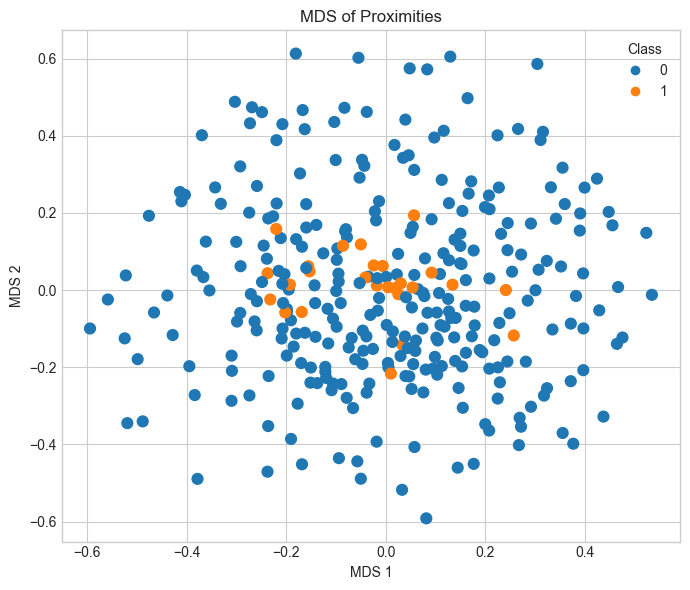

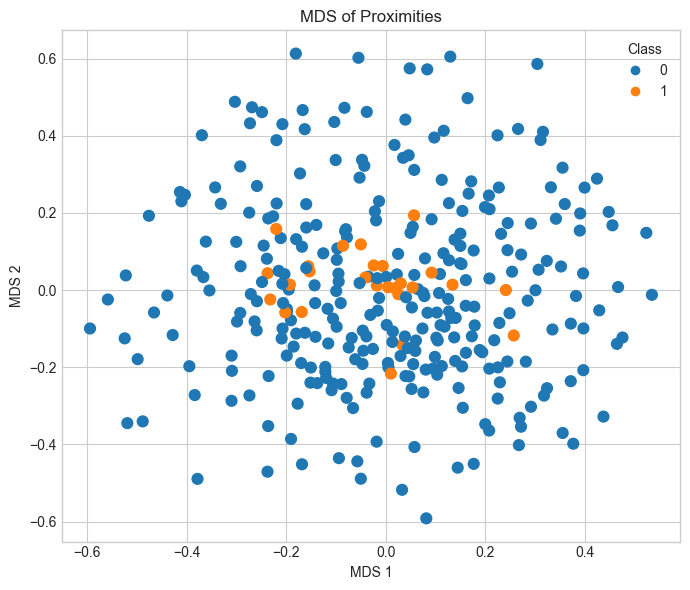

In [36]:
ProxIsolationForest = with_sparse_proximity(IsolationForest)

prox_if = ProxIsolationForest(
    n_estimators=200,
    contamination=MODEL_CONTAMINATION,
    bootstrap=True,
    prox_method='oob',
    random_state=RANDOM_STATE,
)

prox_if.fit(X_scaled)
prox_predictions = (prox_if.predict(X_scaled) == -1).astype(int)
prox_matrix = prox_if.get_proximities()

print(f'Proximity matrix shape: {prox_matrix.shape}')
print(f'Non-zero entries:       {prox_matrix.nnz}')

prox_if.plot_mds(y=prox_predictions)
